# CIS 5450 — Olist Delivery Delay Prediction

This notebook performs exploratory data analysis (EDA) on the cleaned order-level dataset produced in `01_data_cleaning.ipynb`. The goal is to understand the delivery delay label, the distribution of candidate features, and how each feature relates to late delivery, so that the findings can guide hypothesis testing and predictive modeling.

**Prediction setting reminder:** the model predicts delay risk after payment approval and before shipment. Timestamps recorded after approval (carrier handover and customer delivery) are used here only to describe the label, never as features.

## Part 1: Data Loading and Overview

### 1. Imports and file paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Read the cleaned dataset directly from GitHub.
data_path = (
    'https://raw.githubusercontent.com/ZGXJason/CIS5450_FINAL_PROJECT/'
    'main/data/processed/olist_cleaned.csv'
)

# Consistent plot style
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8984'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.titleweight': 'bold',
})

print(f'Cleaned data URL: {data_path}')

Cleaned data URL: https://raw.githubusercontent.com/ZGXJason/CIS5450_FINAL_PROJECT/main/data/processed/olist_cleaned.csv


### 2. Load the cleaned dataset

Parse timestamp columns as datetimes and keep the ZIP code prefix as a string to preserve leading zeros.

In [2]:
timestamp_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'earliest_shipping_limit',
    'latest_shipping_limit'
]

df = pd.read_csv(
    data_path,
    parse_dates=timestamp_cols,
    dtype={'customer_zip_code_prefix': 'string'}
)

print('Dataset shape:', df.shape)
print('Duplicate order IDs:', df['order_id'].duplicated().sum())
print('Total missing values:', df.isna().sum().sum())
display(df.head())

Dataset shape: (95104, 22)
Duplicate order IDs: 0
Total missing values: 0


,order_id,customer_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,item_count,total_price,total_freight,...,latest_shipping_limit,customer_zip_code_prefix,customer_city,customer_state,purchase_month,purchase_weekday,purchase_hour,approval_duration_hours,promised_delivery_days,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,29.99,8.72,...,2017-10-06 11:07:15,03149,sao paulo,SP,10,0,10,0.178333,16,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,118.70,22.76,...,2018-07-30 03:24:27,47813,barreiras,BA,7,1,20,30.713889,18,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,159.90,19.22,...,2018-08-13 08:55:23,75265,vianopolis,GO,8,2,8,0.276111,27,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,45.00,27.20,...,2017-11-23 19:45:59,59296,sao goncalo do amarante,RN,11,5,19,0.298056,27,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,19.90,8.72,...,2018-02-19 20:31:37,09195,santo andre,SP,2,1,21,1.030556,13,0


### 3. Feature availability and summary statistics

#### 3.1 Feature availability checklist

The model makes its prediction at **payment approval** (`order_approved_at`), before the order is handed to the carrier. Any field created after this point would leak information about the outcome. The table below lists every column in the cleaned dataset and states whether it is known at prediction time.

| Column(s) | When it is generated | Known at approval? | Use |
|---|---|---|---|
| `order_purchase_timestamp` | At purchase | ✅ Yes | Source of `purchase_month`, `purchase_weekday`, `purchase_hour` |
| `order_approved_at` | At payment approval (prediction time) | ✅ Yes | Source of `approval_duration_hours` and `promised_delivery_days` |
| `order_estimated_delivery_date` | Shown to the customer at purchase | ✅ Yes | Source of `promised_delivery_days`; also defines the label threshold |
| `earliest_shipping_limit`, `latest_shipping_limit` | Seller handover deadline, set when the order is approved | ✅ Yes | Candidate feature (seller handling window) |
| `item_count`, `total_price`, `total_freight`, `seller_count` | Fixed by the order contents at purchase | ✅ Yes | Model features |
| `customer_state`, `customer_city`, `customer_zip_code_prefix` | Customer address at purchase | ✅ Yes | Model features (geography) |
| `purchase_month`, `purchase_weekday`, `purchase_hour`, `approval_duration_hours`, `promised_delivery_days` | Derived only from the fields above | ✅ Yes | Model features |
| `order_delivered_carrier_date` | When the seller hands the order to the carrier | ❌ No (after prediction time) | **Excluded** — used only for data validation |
| `order_delivered_customer_date` | When the customer receives the order | ❌ No (after prediction time) | **Excluded** — used only to build the label |
| `late_delivery` | Derived from the actual delivery date | ❌ No | **Target label** |
| `order_id`, `customer_id` | Identifiers | — | **Excluded** — no predictive meaning |
| `order_status` | Final status at data extraction | ❌ No | **Already removed** in `01_data_cleaning.ipynb` (constant `delivered`) |

**Selection note:** the cleaned dataset keeps only orders that were eventually delivered, because the label requires an actual delivery date. This is not feature leakage, but it means the model applies to orders that will be delivered. Canceled or undelivered orders are outside its scope.

#### 3.2 Feature groups and summary statistics

Group the columns by role and confirm that every candidate feature is a pre-shipment field from the checklist above.

In [3]:
target_col = 'late_delivery'

# Information available at payment approval
numeric_features = [
    'item_count',
    'seller_count',
    'total_price',
    'total_freight',
    'approval_duration_hours',
    'promised_delivery_days'
]
time_features = ['purchase_month', 'purchase_weekday', 'purchase_hour']
geo_features = ['customer_state', 'customer_city', 'customer_zip_code_prefix']

# Recorded after shipment -> label description only, not model inputs
post_shipment_cols = ['order_delivered_carrier_date', 'order_delivered_customer_date']

# Leakage check: no candidate feature may be a post-shipment column or the label
candidate_features = numeric_features + time_features + geo_features
leaked = set(candidate_features) & set(post_shipment_cols + [target_col])
assert not leaked, f'Post-prediction columns found in features: {leaked}'

print('Numeric features:', numeric_features)
print('Time features:', time_features)
print('Geographic features:', geo_features)
print('Post-shipment columns (excluded from features):', post_shipment_cols)
print('Leakage check passed: no post-shipment column or label in the candidate features.')

print('\nNumeric feature summary:')
display(df[numeric_features].describe().T.round(2))

print('Skewness of numeric features:')
display(df[numeric_features].skew().round(2).to_frame('skewness'))

Numeric features: ['item_count', 'seller_count', 'total_price', 'total_freight', 'approval_duration_hours', 'promised_delivery_days']
Time features: ['purchase_month', 'purchase_weekday', 'purchase_hour']
Geographic features: ['customer_state', 'customer_city', 'customer_zip_code_prefix']
Post-shipment columns (excluded from features): ['order_delivered_carrier_date', 'order_delivered_customer_date']
Leakage check passed: no post-shipment column or label in the candidate features.

Numeric feature summary:


,count,mean,std,min,25%,50%,75%,max
item_count,95104.0,1.14,0.54,1.00,1.00,1.00,1.00,21.00
seller_count,95104.0,1.01,0.12,1.00,1.00,1.00,1.00,5.00
total_price,95104.0,137.19,209.49,0.85,45.90,86.70,149.90,13440.00
total_freight,95104.0,22.78,21.59,0.00,13.84,17.16,24.01,1794.96
approval_duration_hours,95104.0,9.65,19.11,0.00,0.21,0.34,13.54,741.44
promised_delivery_days,95104.0,23.89,8.77,1.00,19.00,23.00,29.00,154.00


Skewness of numeric features:


,skewness
item_count,7.58
seller_count,9.68
total_price,9.91
total_freight,12.36
approval_duration_hours,4.45
promised_delivery_days,0.90


## Part 2: Target Variable Analysis

### 4. Late delivery distribution

Check the class balance of the binary label `late_delivery`.

,count,share
late_delivery,,
On time (0),88596,0.9316
Late (1),6508,0.0684


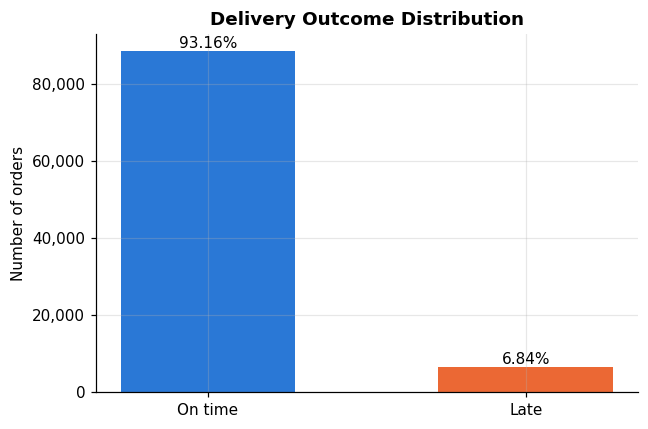

Overall late delivery rate: 6.84%
Imbalance ratio (on time : late): 13.6 : 1


In [4]:
label_counts = df[target_col].value_counts().sort_index()
label_share = df[target_col].value_counts(normalize=True).sort_index()

display(pd.DataFrame({'count': label_counts, 'share': label_share.round(4)})
        .rename(index={0: 'On time (0)', 1: 'Late (1)'}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['On time', 'Late'], label_counts.values, color=[BLUE, ORANGE], width=0.55)
for bar, share in zip(bars, label_share.values):
    ax.annotate(f'{share:.2%}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', fontsize=10)
ax.set_title('Delivery Outcome Distribution')
ax.set_ylabel('Number of orders')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
fig.tight_layout()
plt.show()

overall_late_rate = df[target_col].mean()
print(f'Overall late delivery rate: {overall_late_rate:.2%}')
print(f'Imbalance ratio (on time : late): {label_counts[0] / label_counts[1]:.1f} : 1')

The label is highly imbalanced: about 1 in 15 orders is late. Accuracy alone would be misleading for modeling (predicting "on time" for every order already gives ~93% accuracy), so later modeling should rely on metrics such as recall, precision, PR-AUC, and ROC-AUC, and may need class weighting or resampling.

### 5. Delivery timing relative to the estimate

Measure how many days before or after the estimated date each order arrived. This uses post-delivery information and is only used to understand the label.

Delivery gap (actual - estimated, days):


,delivery_gap_days
count,95104.00
mean,-11.83
std,10.20
min,-147.00
25%,-17.00
50%,-12.00
75%,-7.00
max,188.00


Among late orders — days late:


,days_late
count,6508.00
mean,10.62
std,14.65
min,1.00
25%,3.00
50%,7.00
75%,13.00
max,188.00


Late orders more than 7 days late: 43.87%


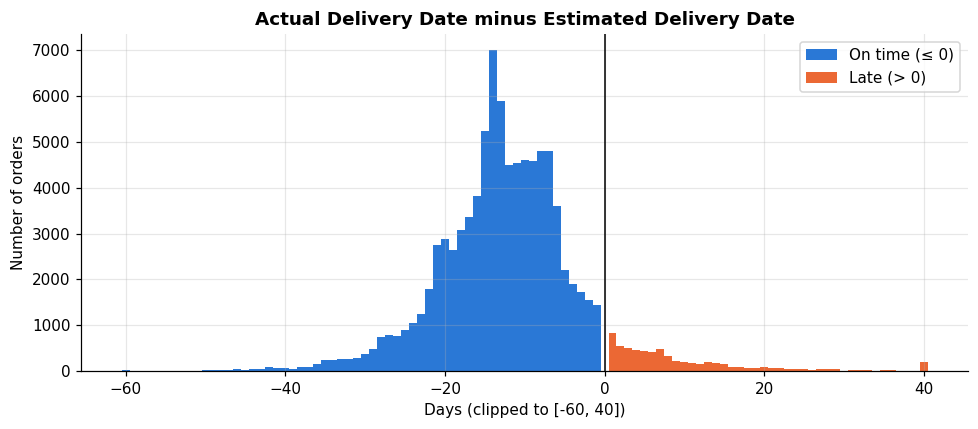

In [5]:
delivery_gap_days = (
    df['order_delivered_customer_date'].dt.normalize() -
    df['order_estimated_delivery_date'].dt.normalize()
).dt.days

print('Delivery gap (actual - estimated, days):')
display(delivery_gap_days.describe().round(2).to_frame('delivery_gap_days'))

late_gap = delivery_gap_days[delivery_gap_days > 0]
print('Among late orders — days late:')
display(late_gap.describe().round(2).to_frame('days_late'))
print('Late orders more than 7 days late:', f'{(late_gap > 7).mean():.2%}')

fig, ax = plt.subplots(figsize=(9, 4))
clipped = delivery_gap_days.clip(-60, 40)
ax.hist(clipped[clipped <= 0], bins=np.arange(-60.5, 0.5, 1), color=BLUE, label='On time (≤ 0)')
ax.hist(clipped[clipped > 0], bins=np.arange(0.5, 41.5, 1), color=ORANGE, label='Late (> 0)')
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Actual Delivery Date minus Estimated Delivery Date')
ax.set_xlabel('Days (clipped to [-60, 40])')
ax.set_ylabel('Number of orders')
ax.legend()
fig.tight_layout()
plt.show()

Most orders arrive well before the estimate (median about 12 days early), which suggests that Olist's estimated delivery dates are conservative. Late orders form a long right tail rather than a cluster just past the deadline.

## Part 3: Feature Distributions

### 6. Numeric feature distributions

Plot the distribution of each numeric pre-shipment feature. Price, freight, and approval duration are strongly right-skewed, so they are shown on a log scale.

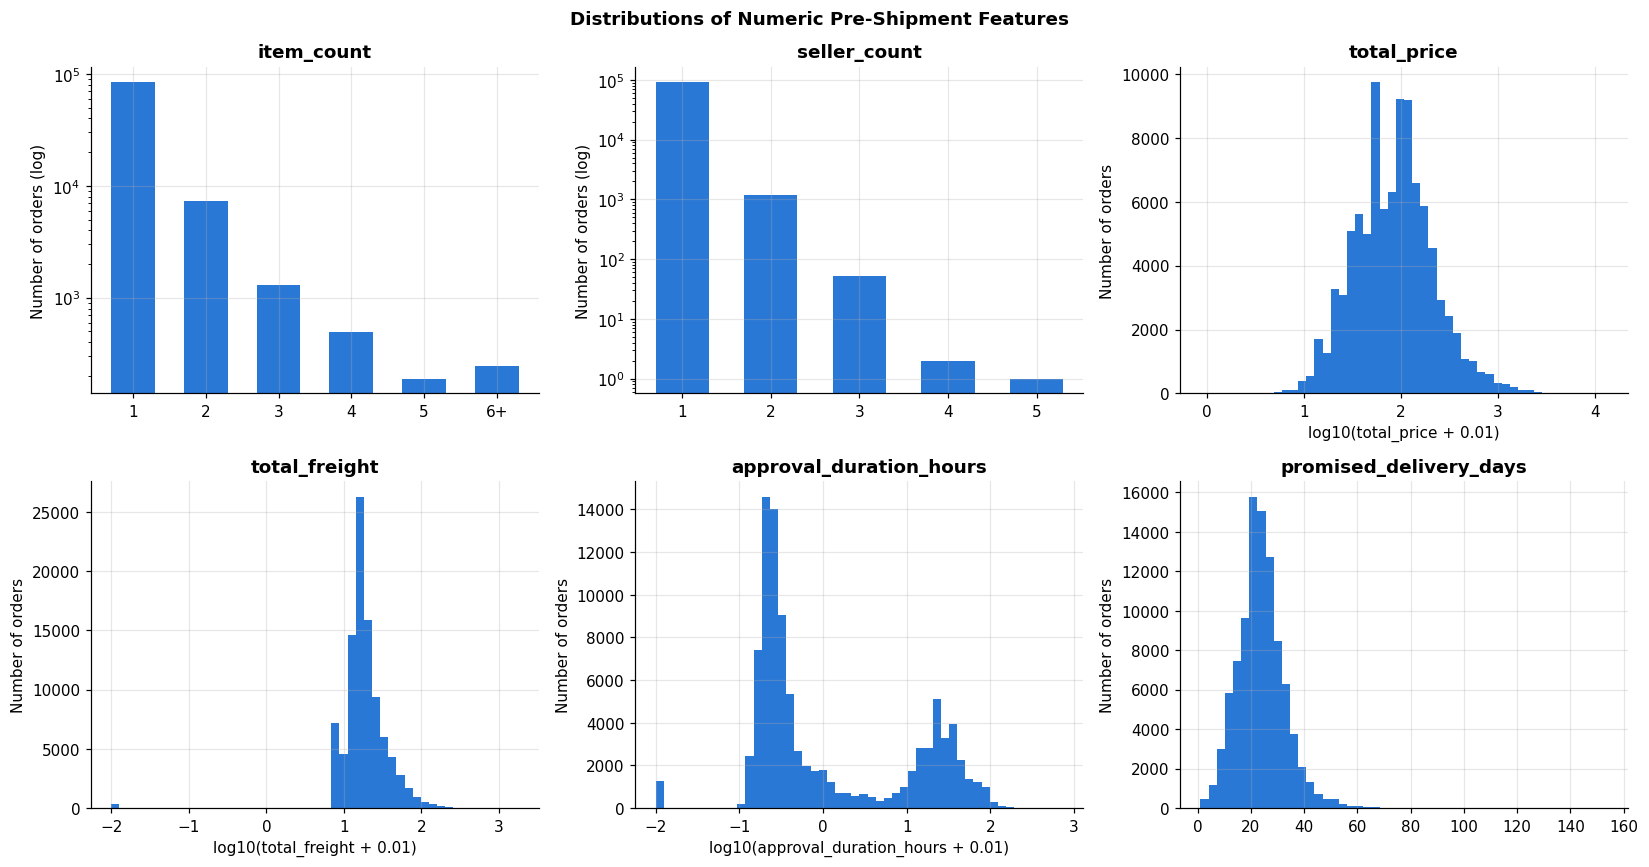

In [6]:
log_scale_cols = {'total_price', 'total_freight', 'approval_duration_hours'}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric_features):
    values = df[col]
    if col in {'item_count', 'seller_count'}:
        counts = values.clip(upper=6).value_counts().sort_index()
        labels = [str(i) if i < 6 else '6+' for i in counts.index]
        ax.bar(labels, counts.values, color=BLUE, width=0.6)
        ax.set_yscale('log')
        ax.set_ylabel('Number of orders (log)')
    elif col in log_scale_cols:
        ax.hist(np.log10(values + 0.01), bins=50, color=BLUE)
        ax.set_xlabel(f'log10({col} + 0.01)')
        ax.set_ylabel('Number of orders')
    else:
        ax.hist(values, bins=50, color=BLUE)
        ax.set_ylabel('Number of orders')
    ax.set_title(col)

fig.suptitle('Distributions of Numeric Pre-Shipment Features', fontweight='bold')
fig.tight_layout()
plt.show()

### 7. Outlier inspection

Count values outside the 1.5 × IQR range for each numeric feature. These extreme values are genuine orders (for example, expensive or bulky items) rather than data errors, so they are retained; tree-based models and rank-based tests are robust to them.

In [7]:
outlier_summary = []
for col in numeric_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append({
        'feature': col,
        'q1': q1,
        'q3': q3,
        'upper_fence': upper,
        'max': df[col].max(),
        'outliers': n_out,
        'outlier_share': n_out / len(df)
    })

display(pd.DataFrame(outlier_summary).set_index('feature').round(3))

print('Orders with zero freight:', (df['total_freight'] == 0).sum())

,q1,q3,upper_fence,max,outliers,outlier_share
feature,,,,,,
item_count,1.000,1.000,1.000,21.000,9496,0.100
seller_count,1.000,1.000,1.000,5.000,1242,0.013
total_price,45.900,149.900,305.900,13440.000,7567,0.080
total_freight,13.840,24.010,39.265,1794.960,9534,0.100
approval_duration_hours,0.214,13.537,33.522,741.444,9411,0.099
promised_delivery_days,19.000,29.000,44.000,154.000,2241,0.024


Orders with zero freight: 325


## Part 4: Feature Relationships with Late Delivery

The helper below computes the late delivery rate with a 95% normal-approximation confidence interval for each group, so that small groups are not over-interpreted.

In [8]:
def late_rate_table(data, group_col):
    """Late delivery rate, order count, and 95% CI per group."""
    table = (
        data.groupby(group_col, observed=True)[target_col]
        .agg(orders='size', late_orders='sum', late_rate='mean')
    )
    se = np.sqrt(table['late_rate'] * (1 - table['late_rate']) / table['orders'])
    table['ci_low'] = (table['late_rate'] - 1.96 * se).clip(lower=0)
    table['ci_high'] = table['late_rate'] + 1.96 * se
    return table


def plot_late_rate(table, ax, title, xlabel, color=BLUE, rotate=0):
    """Bar chart of late rates with CI error bars and an overall-rate reference line."""
    x = [str(i) for i in table.index]
    yerr = [table['late_rate'] - table['ci_low'], table['ci_high'] - table['late_rate']]
    ax.bar(x, table['late_rate'], yerr=yerr, color=color, width=0.6,
           error_kw={'elinewidth': 1, 'capsize': 3, 'ecolor': '#52514e'})
    ax.axhline(overall_late_rate, color=GRAY, linestyle='--', linewidth=1,
               label=f'Overall ({overall_late_rate:.1%})')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Late delivery rate')
    ax.tick_params(axis='x', rotation=rotate)
    ax.legend(loc='best', fontsize=9)

### 8. Order complexity: items and sellers

Compare late rates across the number of items and the number of distinct sellers in an order. This motivates **Hypothesis 1 (order complexity)**.

Late rate by seller group:


,orders,late_orders,late_rate,ci_low,ci_high
seller_group,,,,,
Single-seller,93862,6495,0.0692,0.0676,0.0708
Multi-seller,1242,13,0.0105,0.0048,0.0161


Late rate by item count:


,orders,late_orders,late_rate,ci_low,ci_high
item_group,,,,,
1,85608,6000,0.0701,0.0684,0.0718
2,7278,395,0.0543,0.0491,0.0595
3,1296,64,0.0494,0.0376,0.0612
4+,922,49,0.0531,0.0387,0.0676


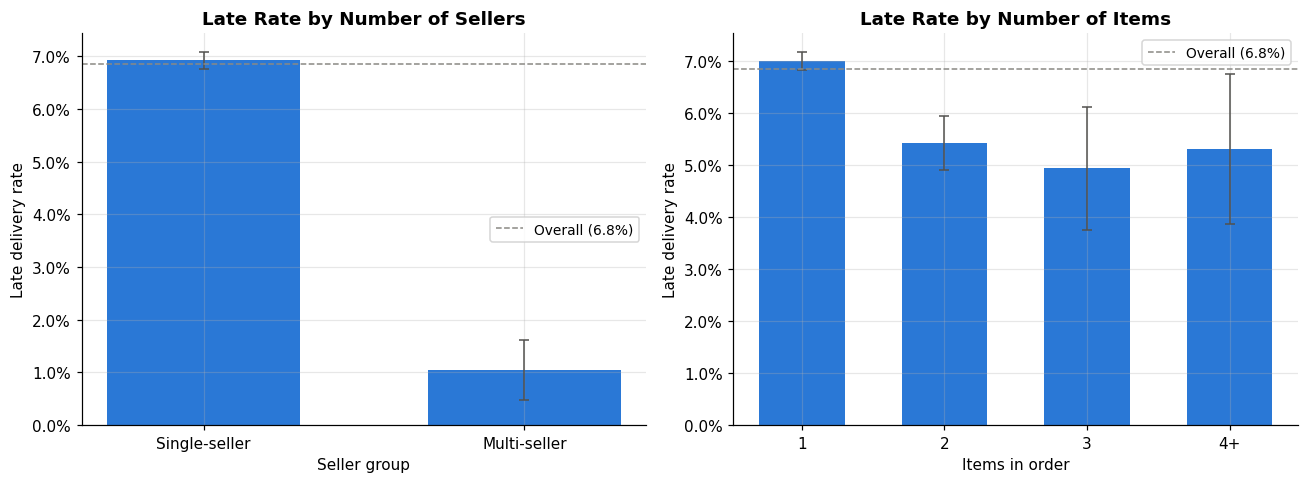

In [9]:
df['seller_group'] = np.where(df['seller_count'] > 1, 'Multi-seller', 'Single-seller')
df['item_group'] = pd.cut(df['item_count'], bins=[0, 1, 2, 3, np.inf],
                          labels=['1', '2', '3', '4+'])

seller_table = late_rate_table(df, 'seller_group').loc[['Single-seller', 'Multi-seller']]
item_table = late_rate_table(df, 'item_group')

print('Late rate by seller group:')
display(seller_table.round(4))
print('Late rate by item count:')
display(item_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_late_rate(seller_table, axes[0], 'Late Rate by Number of Sellers', 'Seller group')
plot_late_rate(item_table, axes[1], 'Late Rate by Number of Items', 'Items in order')
fig.tight_layout()
plt.show()

Contrary to the intuition that more complex orders are riskier, multi-seller orders are late far **less** often than single-seller orders, and orders with more items are also slightly less likely to be late. The multi-seller group is small (about 1.3% of orders), so this difference needs a formal test.

In [10]:
# What else differs between single- and multi-seller orders?
compare_cols = ['item_count', 'total_price', 'total_freight', 'promised_delivery_days',
                'approval_duration_hours']
print('Median order characteristics by seller group:')
display(df.groupby('seller_group')[compare_cols].median().round(2))

Median order characteristics by seller group:


,item_count,total_price,total_freight,promised_delivery_days,approval_duration_hours
seller_group,,,,,
Multi-seller,2.0,159.82,37.18,25.0,0.34
Single-seller,1.0,85.00,17.06,23.0,0.34


Multi-seller orders contain more items, pay more freight, and receive slightly longer promised delivery windows. A longer delivery promise gives more buffer before an order counts as late, which may partly explain the lower late rate.

### 9. Shipping cost

Compare late rates across freight quintiles and between orders above and below the median freight. This motivates **Hypothesis 2 (shipping costs)**. Freight relative to price is also checked, since freight alone partly reflects order size.

Median total freight: R$ 17.16
Late rate by freight group (median split):


,orders,late_orders,late_rate,ci_low,ci_high
freight_group,,,,,
Low freight,47616,2741,0.0576,0.0555,0.0597
High freight,47488,3767,0.0793,0.0769,0.0818


Late rate by freight quintile:


,orders,late_orders,late_rate,ci_low,ci_high
freight_quintile,,,,,
Q1 (lowest),19028,853,0.0448,0.0419,0.0478
Q2,19033,1158,0.0608,0.0574,0.0642
Q3,19043,1461,0.0767,0.0729,0.0805
Q4,18984,1477,0.0778,0.0740,0.0816
Q5 (highest),19016,1559,0.0820,0.0781,0.0859


Late rate by freight-to-price ratio quintile:


,orders,late_orders,late_rate,ci_low,ci_high
freight_ratio_quintile,,,,,
Q1 (lowest),19027,1308,0.0687,0.0651,0.0723
Q2,19016,1267,0.0666,0.0631,0.0702
Q3,19026,1243,0.0653,0.0618,0.0688
Q4,19014,1338,0.0704,0.0667,0.0740
Q5 (highest),19021,1352,0.0711,0.0674,0.0747


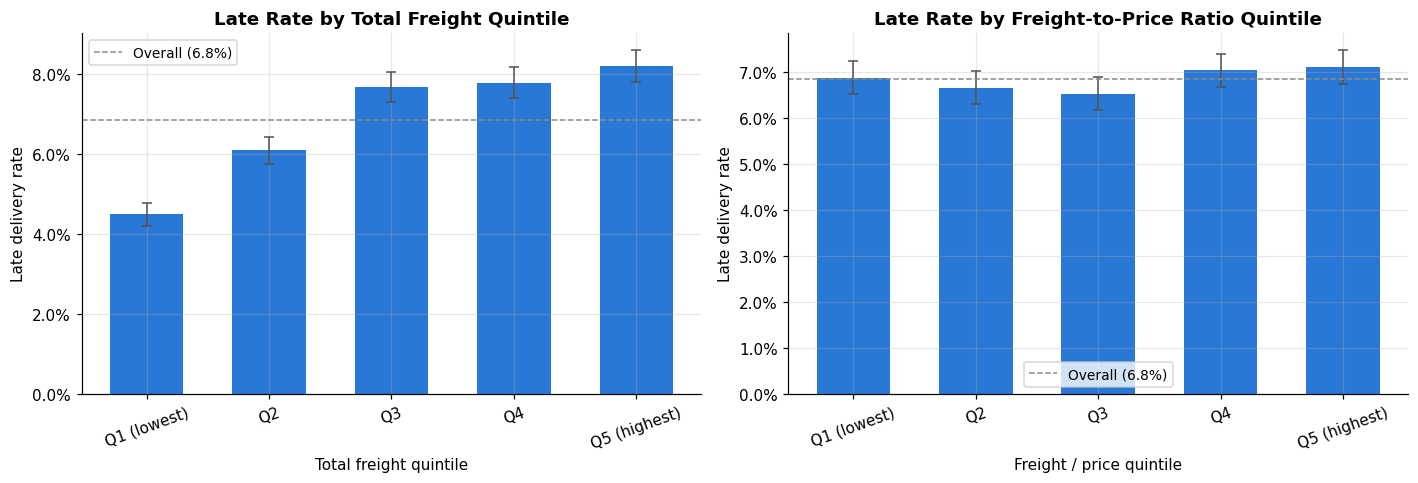

In [11]:
freight_median = df['total_freight'].median()
df['freight_group'] = np.where(df['total_freight'] > freight_median,
                               'High freight', 'Low freight')
df['freight_quintile'] = pd.qcut(df['total_freight'], 5,
                                 labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])
df['freight_ratio'] = df['total_freight'] / df['total_price']
df['freight_ratio_quintile'] = pd.qcut(df['freight_ratio'], 5,
                                       labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])

print(f'Median total freight: R$ {freight_median:.2f}')

freight_group_table = late_rate_table(df, 'freight_group').loc[['Low freight', 'High freight']]
freight_q_table = late_rate_table(df, 'freight_quintile')
freight_ratio_table = late_rate_table(df, 'freight_ratio_quintile')

print('Late rate by freight group (median split):')
display(freight_group_table.round(4))
print('Late rate by freight quintile:')
display(freight_q_table.round(4))
print('Late rate by freight-to-price ratio quintile:')
display(freight_ratio_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_late_rate(freight_q_table, axes[0], 'Late Rate by Total Freight Quintile',
               'Total freight quintile', rotate=20)
plot_late_rate(freight_ratio_table, axes[1], 'Late Rate by Freight-to-Price Ratio Quintile',
               'Freight / price quintile', rotate=20)
fig.tight_layout()
plt.show()

The late rate rises steadily with absolute freight cost, from about 4.5% in the lowest quintile to about 8% in the highest. In contrast, the freight-to-price ratio shows almost no pattern. This suggests that freight matters mainly through what it encodes — most likely shipping **distance** — rather than through cost relative to the order value. Section 13 examines this further.

### 10. Promised delivery window and approval duration

Check whether the length of the promised delivery window and the time taken to approve payment relate to late delivery.

Late rate by promised delivery window (days):


,orders,late_orders,late_rate,ci_low,ci_high
promise_quintile,,,,,
"(0.999, 17.0]",20730,1329,0.0641,0.0608,0.0674
"(17.0, 22.0]",22525,1874,0.0832,0.0796,0.0868
"(22.0, 25.0]",15034,1116,0.0742,0.0700,0.0784
"(25.0, 30.0]",18565,1301,0.0701,0.0664,0.0738
"(30.0, 154.0]",18250,888,0.0487,0.0455,0.0518


Late rate by approval duration:


,orders,late_orders,late_rate,ci_low,ci_high
approval_bucket,,,,,
≤ 1h,61510,3880,0.0631,0.0612,0.0650
1–12h,8664,656,0.0757,0.0701,0.0813
12–24h,9018,622,0.0690,0.0637,0.0742
1–3 days,14130,1185,0.0839,0.0793,0.0884
> 3 days,1782,165,0.0926,0.0791,0.1061


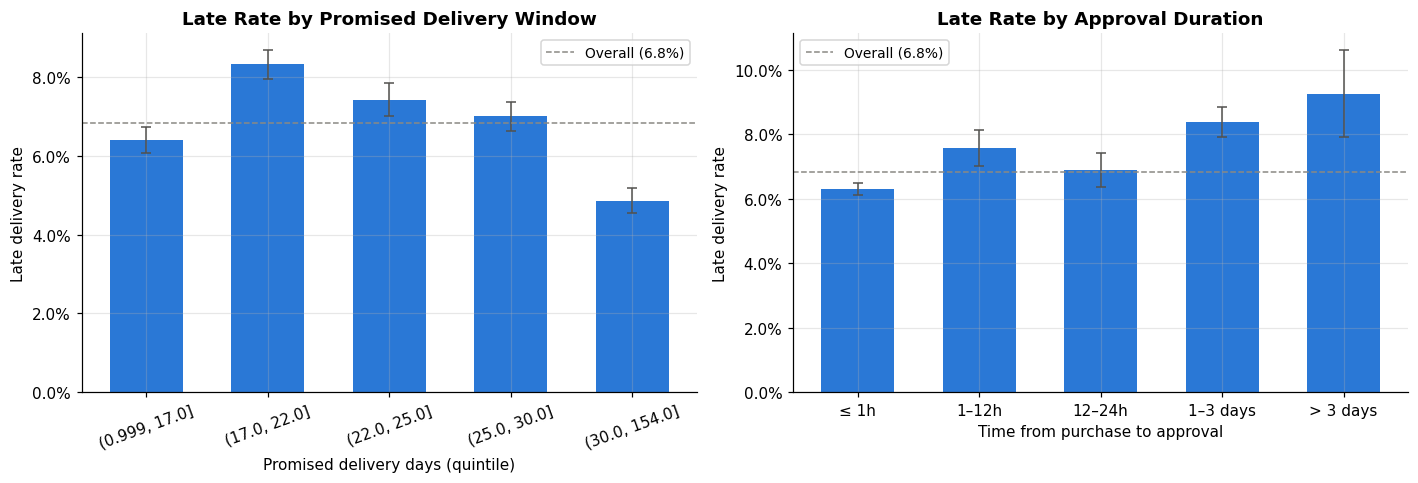

In [12]:
df['promise_quintile'] = pd.qcut(df['promised_delivery_days'], 5)
df['approval_bucket'] = pd.cut(
    df['approval_duration_hours'],
    bins=[-0.01, 1, 12, 24, 72, np.inf],
    labels=['≤ 1h', '1–12h', '12–24h', '1–3 days', '> 3 days']
)

promise_table = late_rate_table(df, 'promise_quintile')
approval_table = late_rate_table(df, 'approval_bucket')

print('Late rate by promised delivery window (days):')
display(promise_table.round(4))
print('Late rate by approval duration:')
display(approval_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_late_rate(promise_table, axes[0], 'Late Rate by Promised Delivery Window',
               'Promised delivery days (quintile)', rotate=20)
plot_late_rate(approval_table, axes[1], 'Late Rate by Approval Duration',
               'Time from purchase to approval')
fig.tight_layout()
plt.show()

Pooled across all orders, the promised window appears to have a non-monotonic (inverted-U) relationship with delay: windows of roughly 18–22 days carry the highest risk, while the longest promises (30+ days) are the safest. Slow payment approval is associated with higher risk, which is consistent with less time being left in the delivery window.

However, the pooled pattern can be misleading. The platform does not assign promised windows at random: remote, higher-risk destinations may receive longer promises. If so, `promised_delivery_days` mixes two effects — a **risk signal** (where the order is going) and **buffer time** (how much slack the order has). The next cell separates these effects by comparing orders across states and within states.

#### 10.1 Promised window across states vs. within states

Compare three views:
1. **Across states:** each state's median promised window against its late rate.
2. **Within states:** late rate by promised-window quintile, computed separately inside the three largest states.
3. **Relative promise:** each order's promised window minus its state's median window, which removes the between-state component.

In [13]:
# 1. Across states: median promise vs. late rate (states with at least 300 orders)
state_promise = (
    df.groupby('customer_state')
    .agg(orders=(target_col, 'size'),
         late_rate=(target_col, 'mean'),
         median_promise=('promised_delivery_days', 'median'))
)
state_promise = state_promise[state_promise['orders'] >= 300]
across_rho = state_promise[['median_promise', 'late_rate']].corr(method='spearman').iloc[0, 1]

print('Across states (>= 300 orders): median promised window vs. late rate')
display(state_promise.sort_values('median_promise').round(3))
print(f'Spearman correlation across states: {across_rho:.2f}')

# 2. Within states: late rate by promised-window quintile inside each large state
within_states = ['SP', 'RJ', 'MG']
quintile_labels = ['Q1 (shortest)', 'Q2', 'Q3', 'Q4', 'Q5 (longest)']
within_rates = {}
for state in within_states:
    sub = df[df['customer_state'] == state]
    q = pd.qcut(sub['promised_delivery_days'], 5, labels=quintile_labels, duplicates='drop')
    within_rates[state] = sub.groupby(q, observed=True)[target_col].mean()
within_rates = pd.DataFrame(within_rates)

print('\nWithin states: late rate by promised-window quintile')
display(within_rates.round(4))

# 3. Relative promise: promised window minus the state's median window
df['relative_promise_days'] = (
    df['promised_delivery_days'] -
    df.groupby('customer_state')['promised_delivery_days'].transform('median')
)
df['relative_promise_quintile'] = pd.qcut(df['relative_promise_days'], 5,
                                          labels=quintile_labels, duplicates='drop')
relative_table = late_rate_table(df, 'relative_promise_quintile')

print('Late rate by relative promise (days vs. state median), pooled over all states:')
display(relative_table.round(4))

Across states (>= 300 orders): median promised window vs. late rate


,orders,late_rate,median_promise
customer_state,,,
SP,39915,0.045,19.0
DF,2041,0.058,24.0
PR,4842,0.041,24.0
MG,11191,0.046,24.0
RJ,12211,0.122,25.0
ES,1968,0.108,25.0
SC,3494,0.083,25.0
MS,696,0.098,26.0
GO,1921,0.066,27.0


Spearman correlation across states: 0.56

Within states: late rate by promised-window quintile


,SP,RJ,MG
promised_delivery_days,,,
Q1 (shortest),0.0661,0.1718,0.0756
Q2,0.0516,0.1408,0.0525
Q3,0.0488,0.1287,0.0446
Q4,0.0324,0.1089,0.0328
Q5 (longest),0.0198,0.0399,0.0169


Late rate by relative promise (days vs. state median), pooled over all states:


,orders,late_orders,late_rate,ci_low,ci_high
relative_promise_quintile,,,,,
Q1 (shortest),21522,1970,0.0915,0.0877,0.0954
Q2,16964,1604,0.0946,0.0902,0.0990
Q3,23772,1668,0.0702,0.0669,0.0734
Q4,16989,810,0.0477,0.0445,0.0509
Q5 (longest),15857,456,0.0288,0.0262,0.0314


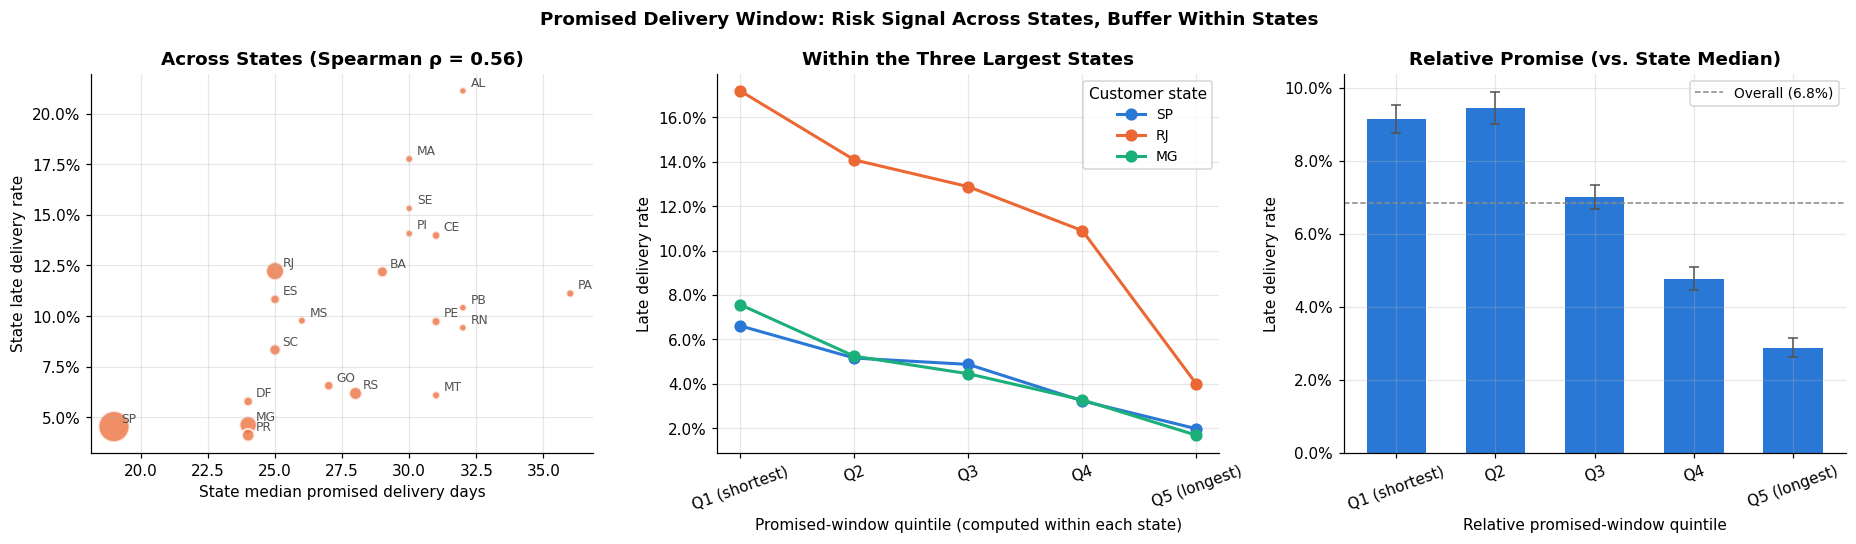

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: across states
ax = axes[0]
sizes = 20 + 400 * state_promise['orders'] / state_promise['orders'].max()
ax.scatter(state_promise['median_promise'], state_promise['late_rate'], s=sizes,
           color=ORANGE, alpha=0.75, edgecolor='white', linewidth=1.5)
for state, row in state_promise.iterrows():
    ax.annotate(state, (row['median_promise'], row['late_rate']), xytext=(5, 3),
                textcoords='offset points', fontsize=8, color='#52514e')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f'Across States (Spearman ρ = {across_rho:.2f})')
ax.set_xlabel('State median promised delivery days')
ax.set_ylabel('State late delivery rate')

# Panel 2: within states
ax = axes[1]
line_colors = {'SP': BLUE, 'RJ': ORANGE, 'MG': '#1baf7a'}
x = np.arange(len(within_rates))
for state in within_states:
    ax.plot(x, within_rates[state], marker='o', linewidth=2, markersize=7,
            color=line_colors[state], label=state)
ax.set_xticks(x)
ax.set_xticklabels(within_rates.index, rotation=20)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('Within the Three Largest States')
ax.set_xlabel('Promised-window quintile (computed within each state)')
ax.set_ylabel('Late delivery rate')
ax.legend(title='Customer state', fontsize=9)

# Panel 3: relative promise, pooled
plot_late_rate(relative_table, axes[2], 'Relative Promise (vs. State Median)',
               'Relative promised-window quintile', rotate=20)

fig.suptitle('Promised Delivery Window: Risk Signal Across States, Buffer Within States',
             fontweight='bold')
fig.tight_layout()
plt.show()

The two views point in **opposite directions**, which is a Simpson's paradox:

- **Across states**, longer promises go with *higher* late rates. The platform gives remote, higher-risk states longer windows (for example, SP has a median of 19 days and a late rate of about 4.5%, while northeastern and northern states receive about 30–36 days and still have late rates above 10%). Here the promised window acts as a **risk signal** for the destination.
- **Within each state**, longer promises go with *lower* late rates, and the decline is steep and monotonic (SP falls from about 6.6% to 2.0%, RJ from about 17% to 4%, MG from about 7.6% to 1.7%). Here the promised window acts as **buffer time**.
- The **relative promise** (days above or below the state median) recovers the buffer effect after pooling: the late rate is flat at about 9% in the two shortest quintiles, then falls steadily to about 3% in the longest, with no inverted U.

The pooled inverted-U shape is therefore a mixture of these two effects, not a real non-monotonic relationship. For modeling, `promised_delivery_days` should not be read as "longer is safer" on its own: it should be used together with geographic features, or replaced by (or paired with) the relative promise feature, so that the model can separate destination risk from buffer time.

### 11. Purchase timing

Examine late rates over calendar time, by weekday, and by hour of purchase.

Sparse months excluded from the trend plot: ['2016-09', '2016-12']


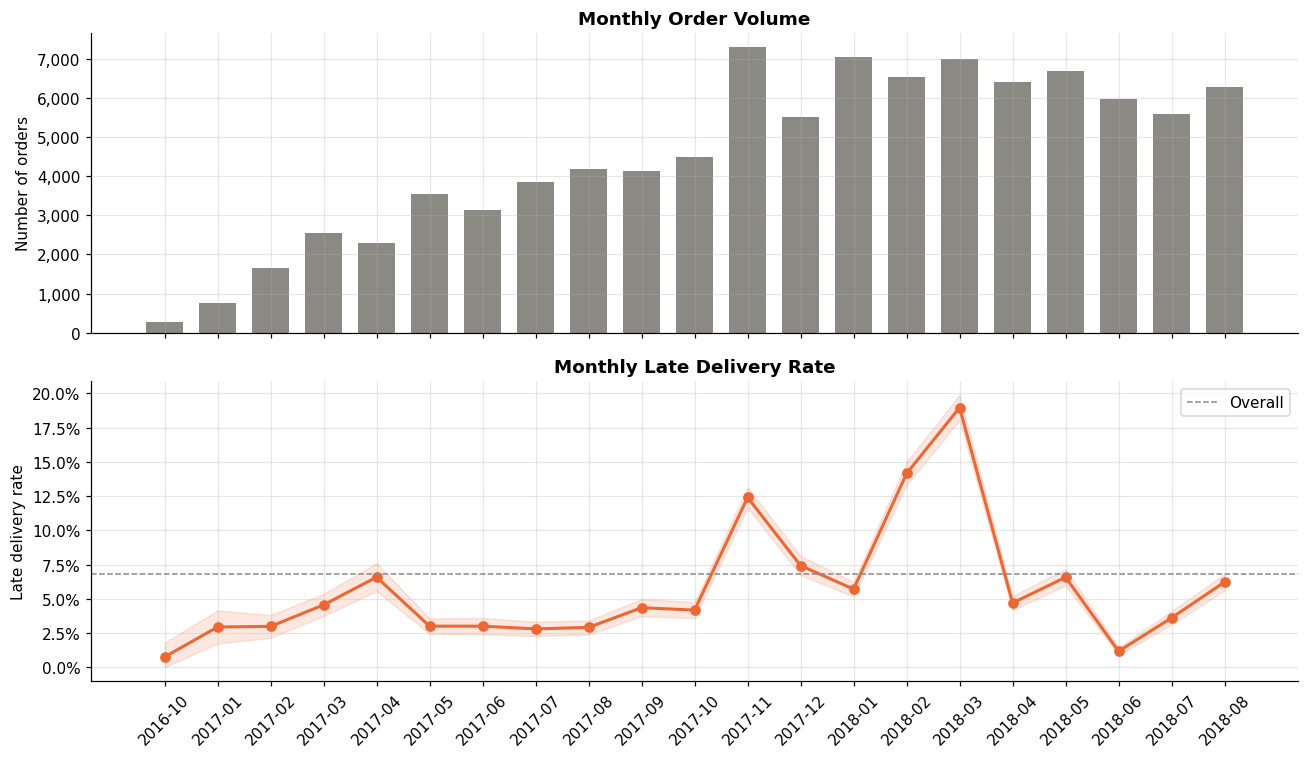

Months with the highest late rates:


,orders,late_orders,late_rate,ci_low,ci_high
purchase_year_month,,,,,
2018-03,7001,1328,0.1897,0.1805,0.1989
2018-02,6543,926,0.1415,0.1331,0.1500
2017-11,7287,904,0.1241,0.1165,0.1316
2017-12,5508,409,0.0743,0.0673,0.0812
2017-04,2279,150,0.0658,0.0556,0.0760


In [15]:
df['purchase_year_month'] = df['order_purchase_timestamp'].dt.to_period('M')
monthly = late_rate_table(df, 'purchase_year_month')

# Drop sparse months at the start of the data (fewer than 100 orders)
sparse_months = monthly.index[monthly['orders'] < 100]
print('Sparse months excluded from the trend plot:', [str(m) for m in sparse_months])
monthly = monthly[monthly['orders'] >= 100]

fig, ax1 = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
x = monthly.index.astype(str)
ax1[0].bar(x, monthly['orders'], color=GRAY, width=0.7)
ax1[0].set_title('Monthly Order Volume')
ax1[0].set_ylabel('Number of orders')
ax1[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

ax1[1].plot(x, monthly['late_rate'], color=ORANGE, marker='o', linewidth=2)
ax1[1].fill_between(x, monthly['ci_low'], monthly['ci_high'], color=ORANGE, alpha=0.15)
ax1[1].axhline(overall_late_rate, color=GRAY, linestyle='--', linewidth=1, label='Overall')
ax1[1].set_title('Monthly Late Delivery Rate')
ax1[1].set_ylabel('Late delivery rate')
ax1[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax1[1].tick_params(axis='x', rotation=45)
ax1[1].legend()
fig.tight_layout()
plt.show()

print('Months with the highest late rates:')
display(monthly.sort_values('late_rate', ascending=False).head(5).round(4))

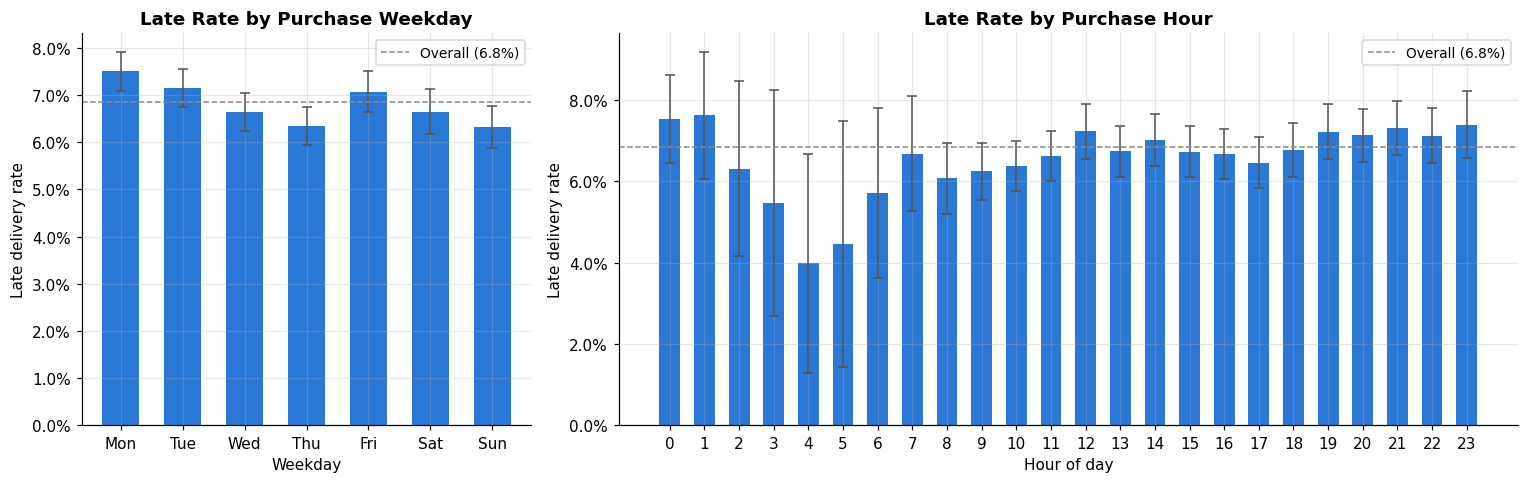

In [16]:
weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_table = late_rate_table(df, 'purchase_weekday')
weekday_table.index = weekday_names
hour_table = late_rate_table(df, 'purchase_hour')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1, 2]})
plot_late_rate(weekday_table, axes[0], 'Late Rate by Purchase Weekday', 'Weekday')
plot_late_rate(hour_table, axes[1], 'Late Rate by Purchase Hour', 'Hour of day')
fig.tight_layout()
plt.show()

Calendar time is the strongest timing signal. Late rates spike in **November 2017** (Black Friday) and in **February–March 2018**, reaching 12–19%, while the remaining months mostly stay between 1% and 7%. Weekday and hour effects are small by comparison; late-night and early-morning hours have wider intervals because fewer orders are placed then. Because late risk varies so much over time, a time-based train/test split is advisable for modeling, and time is a potential confounder for the hypothesis tests.

### 12. Customer geography

Compare late rates and order volume across customer states.

Late rate by customer state:


,orders,late_orders,late_rate,ci_low,ci_high
customer_state,,,,,
AM,144,4,0.0278,0.0009,0.0546
RO,242,7,0.0289,0.0078,0.0500
AP,67,2,0.0299,0.0000,0.0706
AC,77,3,0.0390,0.0000,0.0822
PR,4842,199,0.0411,0.0355,0.0467
SP,39915,1812,0.0454,0.0434,0.0474
MG,11191,517,0.0462,0.0423,0.0501
DF,2041,118,0.0578,0.0477,0.0679
MT,871,53,0.0608,0.0450,0.0767


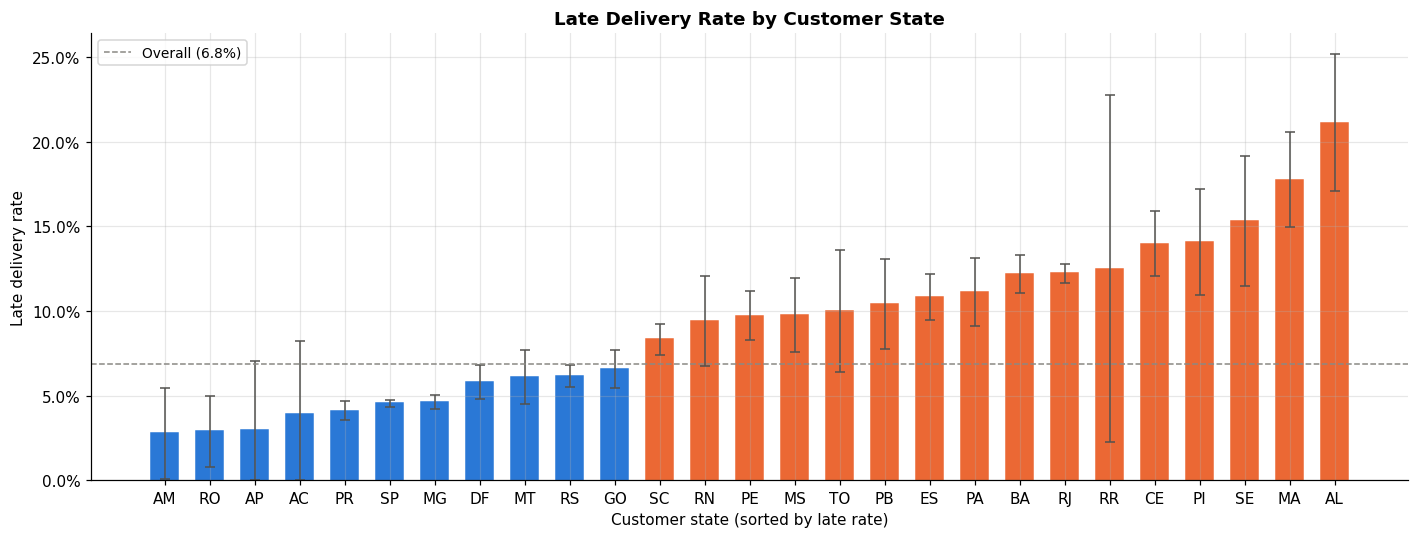

Share of orders in SP, RJ, MG: 66.58%


In [17]:
state_table = late_rate_table(df, 'customer_state').sort_values('late_rate')

print('Late rate by customer state:')
display(state_table.round(4))

fig, ax = plt.subplots(figsize=(13, 5))
colors = [ORANGE if r > overall_late_rate else BLUE for r in state_table['late_rate']]
plot_late_rate(state_table, ax, 'Late Delivery Rate by Customer State',
               'Customer state (sorted by late rate)')
for patch, c in zip(ax.patches, colors):
    patch.set_color(c)
fig.tight_layout()
plt.show()

top_states = state_table.sort_values('orders', ascending=False).head(3)
print('Share of orders in SP, RJ, MG:', f"{top_states['orders'].sum() / len(df):.2%}")

Geography is a major driver. São Paulo (SP), which holds about 42% of all orders and is home to most sellers, has a late rate of only about 4.5%. Northeastern states such as AL, MA, SE, CE, and PI exceed 14%, and Rio de Janeiro (RJ) is notably high at about 12% despite being close to SP. Small northern states (AM, RO, AP, AC) have low rates but very few orders and wide confidence intervals.

## Part 5: Correlation and Confounding

### 13. Correlation among numeric features

Use Spearman rank correlation, which is robust to the heavy skew and outliers observed above.

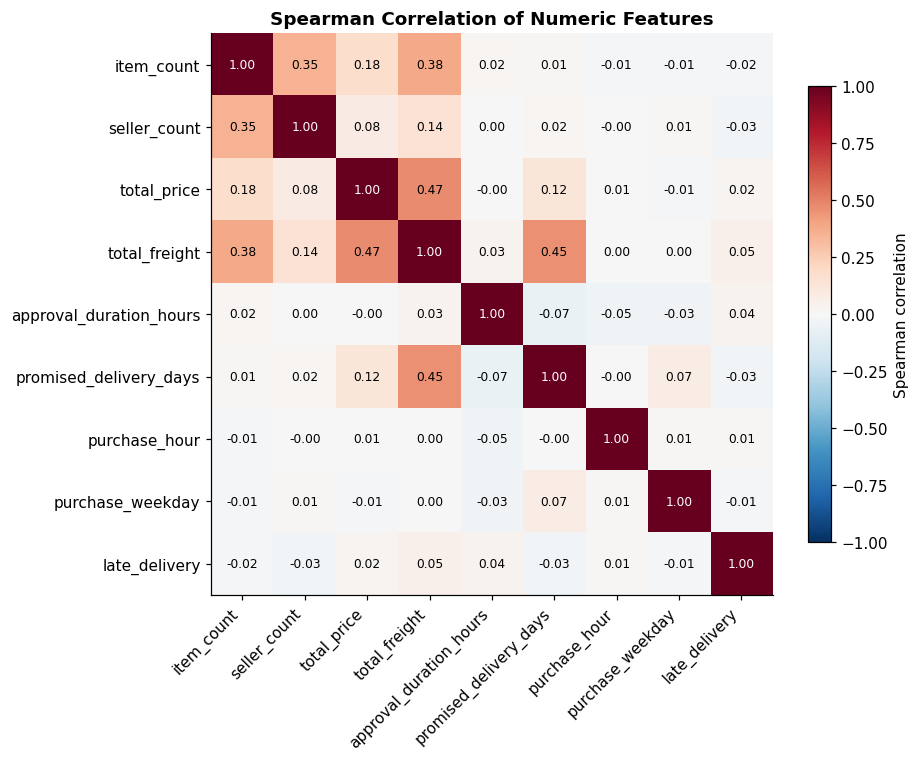

Correlation with late_delivery:


,spearman_with_late
total_freight,0.053
approval_duration_hours,0.035
seller_count,-0.026
promised_delivery_days,-0.026
total_price,0.024
item_count,-0.020
purchase_weekday,-0.012
purchase_hour,0.009


In [18]:
corr_cols = numeric_features + ['purchase_hour', 'purchase_weekday', target_col]
corr = df[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha='right')
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr.iloc[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(val) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8, label='Spearman correlation')
ax.set_title('Spearman Correlation of Numeric Features')
fig.tight_layout()
plt.show()

print('Correlation with late_delivery:')
display(corr[target_col].drop(target_col).sort_values(key=abs, ascending=False)
        .round(3).to_frame('spearman_with_late'))

No single numeric feature has a strong monotonic correlation with the label (all |ρ| < 0.06), which is common for rare-event outcomes and suggests that delay risk comes from **interactions** (for example, geography × time × freight) rather than any one variable. Total freight is moderately correlated with price, item count, and the promised window (ρ ≈ 0.4–0.5), so these features partly overlap.

### 14. Confounding check for the hypotheses

Before testing, check whether the group comparisons could be explained by geography or time.

**Shipping cost vs. geography:** if high-freight orders are concentrated in distant states, the freight effect may simply reflect location.

Share of orders shipped to SP, by freight group:


customer_in_sp,Other states,SP
freight_group,,
High freight,0.764,0.236
Low freight,0.397,0.603


Late rate by freight group within the 8 largest states:


freight_group,Low freight,High freight,difference
customer_state,,,
SP,0.0439,0.0492,0.0053
RJ,0.1161,0.1267,0.0107
MG,0.0443,0.0476,0.0033
RS,0.0698,0.0569,-0.0130
PR,0.0429,0.0397,-0.0032
SC,0.0985,0.0734,-0.0251
BA,0.1144,0.1238,0.0094
DF,0.0505,0.0637,0.0131


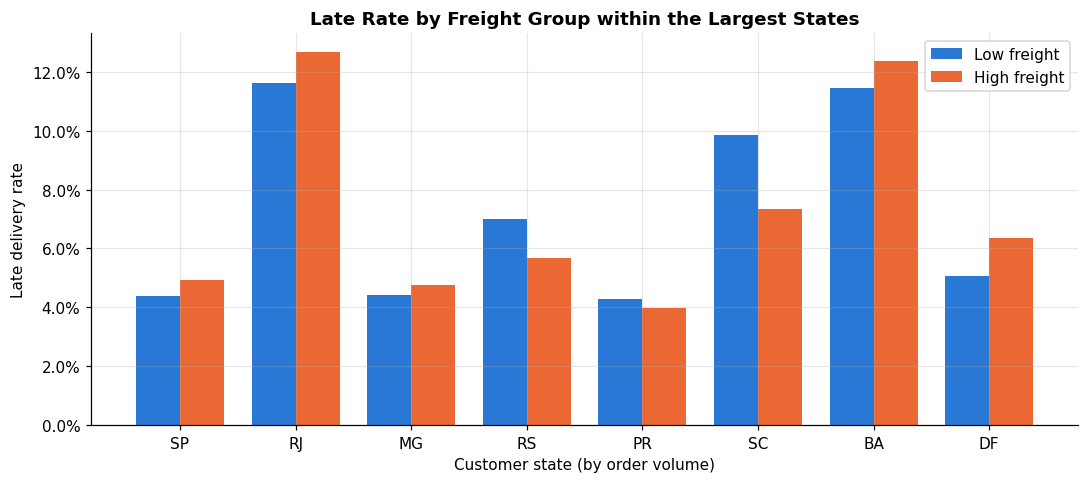

In [19]:
df['customer_in_sp'] = np.where(df['customer_state'] == 'SP', 'SP', 'Other states')

print('Share of orders shipped to SP, by freight group:')
display(pd.crosstab(df['freight_group'], df['customer_in_sp'], normalize='index').round(3))

# Late rate by freight group within each of the largest states
largest_states = df['customer_state'].value_counts().head(8).index
within_state = (
    df[df['customer_state'].isin(largest_states)]
    .pivot_table(index='customer_state', columns='freight_group',
                 values=target_col, aggfunc='mean')
    [['Low freight', 'High freight']]
)
within_state['difference'] = within_state['High freight'] - within_state['Low freight']
within_state = within_state.loc[largest_states]
print('Late rate by freight group within the 8 largest states:')
display(within_state.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
pos = np.arange(len(within_state))
w = 0.38
ax.bar(pos - w / 2, within_state['Low freight'], width=w, color=BLUE, label='Low freight')
ax.bar(pos + w / 2, within_state['High freight'], width=w, color=ORANGE, label='High freight')
ax.set_xticks(pos)
ax.set_xticklabels(within_state.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('Late Rate by Freight Group within the Largest States')
ax.set_xlabel('Customer state (by order volume)')
ax.set_ylabel('Late delivery rate')
ax.legend()
fig.tight_layout()
plt.show()

High-freight orders go to customers outside SP far more often than low-freight orders. Within individual states, the gap between high- and low-freight orders becomes small and inconsistent in direction. Much of the overall freight effect therefore appears to be explained by **customer location**, so the hypothesis test for shipping costs should include a state-stratified check.

**Order complexity vs. time:** multi-seller orders became more common over time, and late rates vary sharply by month, so the comparison is also checked within purchase months.

In [20]:
df['purchase_quarter'] = df['order_purchase_timestamp'].dt.to_period('Q')
multi_share_by_quarter = (
    df.groupby('purchase_quarter')
    .agg(orders=('seller_count', 'size'),
         multi_seller_share=('seller_count', lambda s: (s > 1).mean()))
)

within_month = (
    df[df['purchase_year_month'].isin(monthly.index)]
    .pivot_table(index='purchase_year_month', columns='seller_group',
                 values=target_col, aggfunc=['mean', 'size'])
)
within_month.columns = [f'{stat}_{grp}' for stat, grp in within_month.columns]

print('Share of multi-seller orders by purchase quarter:')
display(multi_share_by_quarter.round(4))

print('Months where multi-seller orders are late more often than single-seller orders:',
      (within_month['mean_Multi-seller'] > within_month['mean_Single-seller']).sum(),
      'of', len(within_month))

Share of multi-seller orders by purchase quarter:


,orders,multi_seller_share
purchase_quarter,,
2016Q3,1,0.0000
2016Q4,266,0.0113
2017Q1,4934,0.0043
2017Q2,8941,0.0084
2017Q3,12180,0.0135
2017Q4,17273,0.0125
2018Q1,20589,0.0118
2018Q2,19063,0.0168
2018Q3,11857,0.0169


Months where multi-seller orders are late more often than single-seller orders: 0 of 21


In none of the 21 months are multi-seller orders late more often than single-seller orders, so the gap is not simply a product of when those orders were placed. A month-stratified test will confirm this formally.

## Part 6: EDA Summary

### 1. Key Findings

1. **Imbalanced target:** 6.84% of orders are late (about 14 on-time orders per late order). Most orders arrive about 12 days earlier than estimated, so Olist's delivery estimates are conservative.
2. **Order complexity:** multi-seller orders are late much less often (about 1%) than single-seller orders (about 7%), and orders with more items are slightly less risky. Multi-seller orders also get longer delivery promises.
3. **Shipping cost:** the late rate rises from about 4.5% to about 8% across freight quintiles, but the freight-to-price ratio shows no pattern. High-freight orders are concentrated outside SP, and the freight gap mostly disappears within states.
4. **Geography:** late rates range from about 3% to over 20% across states. SP is low-risk, while the Northeast and RJ are high-risk.
5. **Time:** late rates spike in Nov 2017 and Feb–Mar 2018 (up to about 19%). Weekday and hour effects are minor.
6. **Promised window (Simpson's paradox):** across states, longer promises go with higher late rates because remote, risky states receive longer windows. Within a state, longer promises are strongly protective (SP: about 6.6% → 2.0%). The window is both a destination risk signal and buffer time.
7. **Approval duration:** slow payment approval is associated with higher risk.
8. **Weak single-feature correlations:** all |ρ| < 0.06 with the label, which suggests that non-linear models capturing interactions will be needed.

### 2. Implications for Hypothesis Testing

- **Hypothesis 1 (order complexity):** test single- vs. multi-seller late rates; add a **month-stratified** permutation test to control for time.
- **Hypothesis 2 (shipping costs):** test high- vs. low-freight late rates (median split); add a **state-stratified** permutation test, because geography is a strong confounder.

### 3. Implications for Modeling

- Use imbalance-aware metrics (PR-AUC, recall, F1) and class weighting.
- Use a **time-based** train/test split because the late rate shifts strongly across months.
- Encode `customer_state` (for example, with target encoding or one-hot encoding), as it is one of the strongest signals.
- Use `promised_delivery_days` together with geography, and consider the relative promise (days vs. state median) as an additional feature.
- Keep post-shipment timestamps (`order_delivered_carrier_date`, `order_delivered_customer_date`) out of the feature set, following the feature availability checklist in Section 3.1.
- The dataset contains only delivered orders, so the model applies to orders that are eventually delivered.